<a href="https://colab.research.google.com/github/Clestialcosmos/Machine-learning1.0/blob/main/Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install numpy pandas matplotlib scikit-learn

1. Implementation of Simple Linear Regression
Objective: Predict a continuous dependent variable using a single independent variable.

Example: Predicting salary based on years of experience.

Coefficient: [5000.]
Intercept: 19999.999999999996
Predicted Salary: [70000.]
R2 Score: 1.0


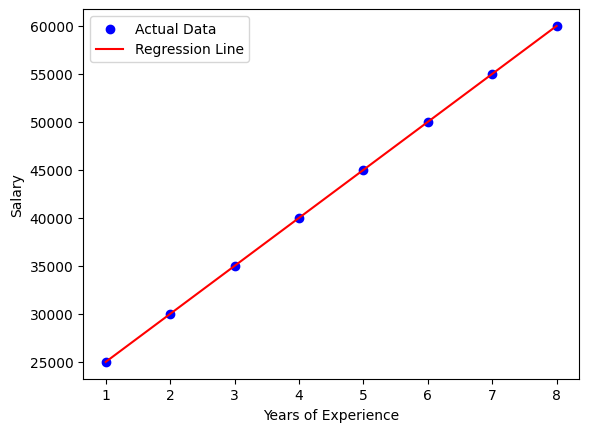

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8]).reshape(-1, 1)
y = np.array([25000, 30000, 35000, 40000,
              45000, 50000, 55000, 60000])

# Create and train model
model = LinearRegression()
model.fit(X, y)

# Prediction
y_pred = model.predict(X)

# Model parameters
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)
print("Predicted Salary:", model.predict([[10]]))
print("R2 Score:", model.score(X, y))

# Visualization
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, y_pred, color="red", label="Regression Line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

2. Implementation of Multiple Linear Regression
Objective: Predict a continuous dependent variable using multiple independent variables.

Dataset: Diabetes dataset.

Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
Mean Squared Error: 2900.193628493482
R2 Score: 0.4526027629719195


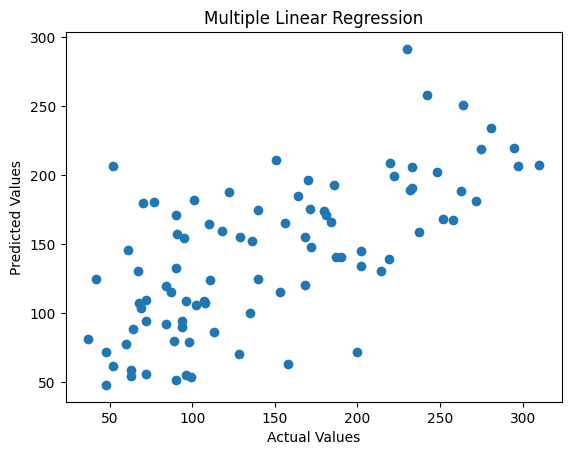

In [3]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Load dataset
data = load_diabetes()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# Visualization
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Multiple Linear Regression")
plt.show()

3. Implementation of Logistic Regression
Objective: Classify data into different categories.

Dataset: Breast Cancer Wisconsin dataset (binary classification).

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create and train model
model = LogisticRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n",
      classification_report(y_test, y_pred))

Accuracy: 0.9736842105263158
Confusion Matrix:
 [[41  2]
 [ 1 70]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



4. Implementation of Regression Models with Regularization
Objective: Reduce overfitting by adding a penalty to the regression model.

This program implements Linear Regression, Ridge Regression (L2), Lasso Regression (L1) and Elastic Net Regression (L1 + L2).

In [5]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = load_diabetes()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Regression models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=1.0),
    "Elastic Net": ElasticNet(alpha=1.0, l1_ratio=0.5)
}

# Train and evaluate models
for name, model in models.items():

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("\nModel:", name)
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("R2 Score:", r2_score(y_test, y_pred))
    print("Coefficients:", model.coef_)


Model: Linear Regression
MSE: 2900.1936284934823
R2 Score: 0.45260276297191926
Coefficients: [  1.75375799 -11.51180908  25.60712144  16.82887167 -44.44885564
  24.64095356   7.67697768  13.1387839   35.16119521   2.35136365]

Model: Ridge Regression
MSE: 2892.0145657501726
R2 Score: 0.45414652070698225
Coefficients: [  1.80734179 -11.44818951  25.73269892  16.73429974 -34.67195409
  17.05307485   3.36991411  11.76426044  31.3783838    2.45813922]

Model: Lasso Regression
MSE: 2824.568094049959
R2 Score: 0.46687670944102466
Coefficients: [ 0.68703212 -9.29751904 26.21922482 15.65731357 -8.2281718  -0.
 -9.02408714  3.42086059 22.63646533  2.09864712]

Model: Elastic Net
MSE: 2888.7047200595607
R2 Score: 0.45477123774939965
Coefficients: [ 1.82391583 -6.04219601 18.96178774 12.26520609 -1.17986901 -2.88035238
 -8.43791893  5.84628711 14.41995058  5.01279769]


5. Implementation of Dimensionality Reduction using PCA
Objective: Reduce the number of features while retaining as much variance as possible.

Dataset: Iris dataset (4 features reduced to 2 principal components).

        PC1       PC2  Target
0 -2.264703  0.480027       0
1 -2.080961 -0.674134       0
2 -2.364229 -0.341908       0
3 -2.299384 -0.597395       0
4 -2.389842  0.646835       0
Original Shape: (150, 4)
Reduced Shape: (150, 2)
Explained Variance: [0.72962445 0.22850762]
Total Variance: 0.9581320720000166


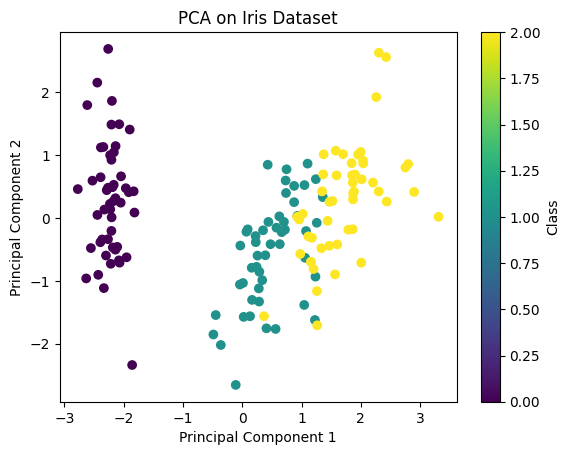

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
data = load_iris()

X = data.data
y = data.target

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame
df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df["Target"] = y

print(df.head())

# Evaluation
print("Original Shape:", X.shape)
print("Reduced Shape:", X_pca.shape)
print("Explained Variance:", pca.explained_variance_ratio_)
print("Total Variance:", sum(pca.explained_variance_ratio_))

# Visualization
plt.scatter(df["PC1"], df["PC2"], c=y, cmap="viridis")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Iris Dataset")
plt.colorbar(label="Class")
plt.show()

6. Implementation of Support Vector Machine (SVM)
Objective: Classify data by finding an optimal separating boundary between classes.

Dataset: Iris dataset.

In [7]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Load dataset
data = load_iris()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create SVM model
model = SVC(kernel="linear", C=1.0)

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n",
      classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667
Confusion Matrix:
 [[10  0  0]
 [ 0  8  1]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.89      0.94         9
           2       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30



7. Implementation of Decision Tree on Real-World Dataset
Objective: Classify data using a tree-like structure of decision rules.

Dataset: Real-world Iris flower dataset.

Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


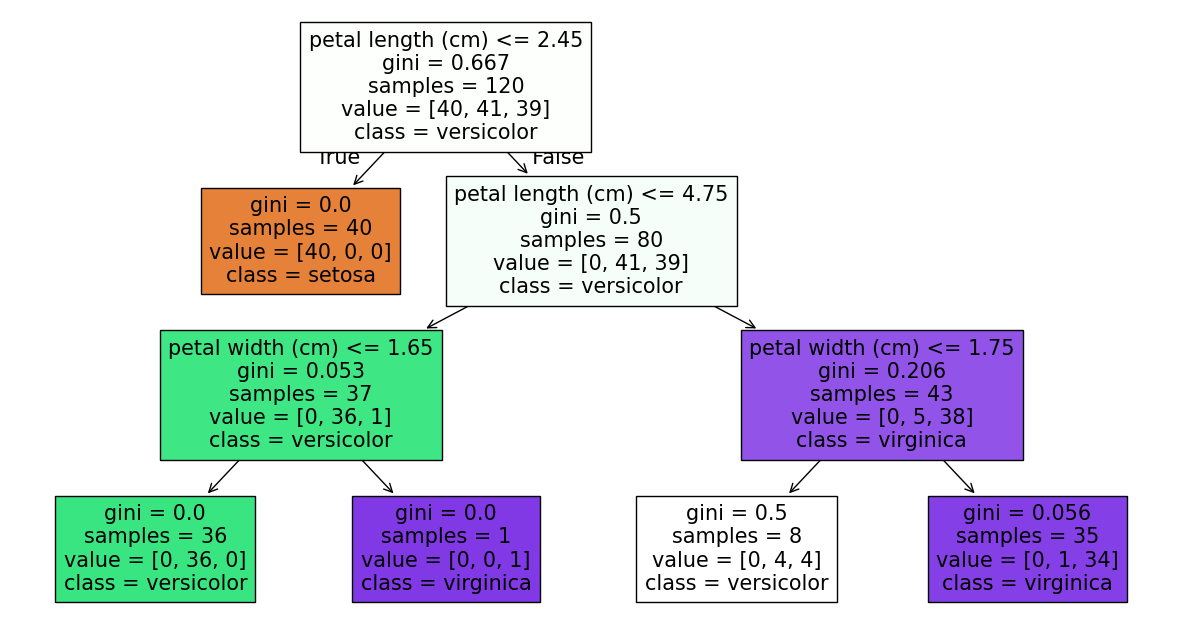

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

# Load dataset
data = load_iris()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Visualize Decision Tree
plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True
)

plt.show()

8. Implementation of Naïve Bayes Classifier
Objective: Classify data using Bayes' theorem and the assumption of conditional independence between features.

Dataset: Iris dataset.

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Load dataset
data = load_iris()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Naive Bayes model
model = GaussianNB()

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n",
      classification_report(y_test, y_pred))

Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



9. Implementation of K-Means Clustering
Objective: Divide unlabeled data into K clusters based on similarity.

Dataset: Artificial dataset generated using make_blobs().

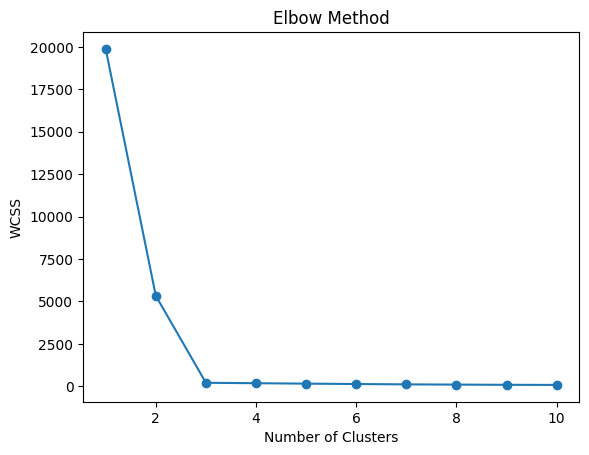

Cluster Centers:
 [[-2.58361866  9.03185632]
 [-6.88217395 -6.94243433]
 [ 4.70421356  1.99562444]]
WCSS: 204.06943840478857
Silhouette Score: 0.9083834454815235


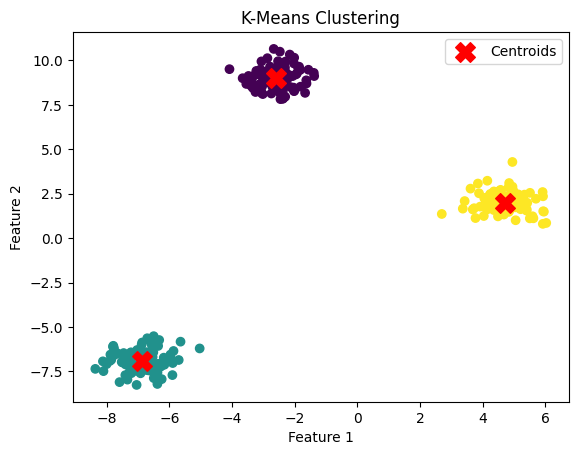

In [10]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Generate dataset
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.60,
    random_state=42
)

# Elbow Method
wcss = []

for i in range(1, 11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    wcss.append(model.inertia_)

# Plot Elbow Method
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Create K-Means model
model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train and predict clusters
y_pred = model.fit_predict(X)

# Cluster centers
centers = model.cluster_centers_

print("Cluster Centers:\n", centers)
print("WCSS:", model.inertia_)
print("Silhouette Score:", silhouette_score(X, y_pred))

# Visualize clusters
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="viridis")

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

# Machine Learning – Quick Revision

## 1. Algorithm Summary

| Algorithm | Learning Type | Scikit-learn Class | Evaluation Metric |
|---|---|---|---|
| Simple Linear Regression | Supervised | LinearRegression | R², MSE |
| Multiple Linear Regression | Supervised | LinearRegression | R², MSE |
| Logistic Regression | Supervised | LogisticRegression | Accuracy |
| Ridge Regression | Supervised | Ridge | R², MSE |
| Lasso Regression | Supervised | Lasso | R², MSE |
| PCA | Unsupervised | PCA | Explained Variance |
| SVM | Supervised | SVC | Accuracy |
| Decision Tree | Supervised | DecisionTreeClassifier | Accuracy |
| Naïve Bayes | Supervised | GaussianNB | Accuracy |
| K-Means | Unsupervised | KMeans | WCSS, Silhouette |

## 2. Feature Scaling Requirements

| Algorithm | Scaling Recommended? |
|---|---|
| Simple Linear Regression | Optional |
| Multiple Linear Regression | Optional |
| Logistic Regression | Yes |
| Ridge and Lasso | Yes |
| PCA | Yes, generally |
| SVM | Yes |
| Decision Tree | No |
| Gaussian Naïve Bayes | Generally No |
| K-Means | Yes |

**Important:** Always perform train-test splitting before
feature scaling to prevent data leakage.

- Training Data: fit_transform()
- Testing Data: transform()

In [12]:
import pandas as pd

# Create the dataframe representing the quick revision table
data_summary = {
    "Algorithm": [
        "Simple Linear Regression",
        "Multiple Linear Regression",
        "Logistic Regression",
        "Ridge Regression",
        "Lasso Regression",
        "PCA",
        "SVM",
        "Decision Tree",
        "Gaussian Naïve Bayes",
        "K-Means"
    ],
    "Learning Type": [
        "Supervised",
        "Supervised",
        "Supervised",
        "Supervised",
        "Supervised",
        "Unsupervised",
        "Supervised",
        "Supervised",
        "Supervised",
        "Unsupervised"
    ],
    "Scikit-learn Class": [
        "LinearRegression",
        "LinearRegression",
        "LogisticRegression",
        "Ridge",
        "Lasso",
        "PCA",
        "SVC",
        "DecisionTreeClassifier",
        "GaussianNB",
        "KMeans"
    ],
    "Evaluation Metric": [
        "R², MSE",
        "R², MSE",
        "Accuracy",
        "R², MSE",
        "R², MSE",
        "Explained Variance",
        "Accuracy",
        "Accuracy",
        "Accuracy",
        "WCSS, Silhouette"
    ],
    "Feature Scaling": [
        "Optional",
        "Optional",
        "Yes",
        "Yes",
        "Yes",
        "Yes, generally",
        "Yes",
        "No",
        "Generally No",
        "Yes"
    ]
}

df = pd.DataFrame(data_summary)

def highlight_scaling(value):
    if value == "Yes":
        return "background-color: #dcfce7; color: #166534"
    elif value in ["No", "Generally No"]:
        return "background-color: #fee2e2; color: #991b1b"
    else:
        return "background-color: #fef3c7; color: #92400e"

styled_df = df.style.map(
    highlight_scaling,
    subset=["Feature Scaling"]
).set_table_styles([
    {
        "selector": "th",
        "props": [
            ("background-color", "#1e293b"),
            ("color", "white"),
            ("padding", "12px"),
            ("text-align", "center")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("padding", "10px"),
            ("text-align", "center"),
            ("border", "1px solid #dddddd")
        ]
    }
])

display(styled_df)

,Algorithm,Learning Type,Scikit-learn Class,Evaluation Metric,Feature Scaling
0,Simple Linear Regression,Supervised,LinearRegression,"R², MSE",Optional
1,Multiple Linear Regression,Supervised,LinearRegression,"R², MSE",Optional
2,Logistic Regression,Supervised,LogisticRegression,Accuracy,Yes
3,Ridge Regression,Supervised,Ridge,"R², MSE",Yes
4,Lasso Regression,Supervised,Lasso,"R², MSE",Yes
5,PCA,Unsupervised,PCA,Explained Variance,"Yes, generally"
6,SVM,Supervised,SVC,Accuracy,Yes
7,Decision Tree,Supervised,DecisionTreeClassifier,Accuracy,No
8,Gaussian Naïve Bayes,Supervised,GaussianNB,Accuracy,Generally No
9,K-Means,Unsupervised,KMeans,"WCSS, Silhouette",Yes
